# Notebook 03 — EDA and Visual Analytics

**Purpose:** Perform meaningful exploratory data analysis to discover patterns in diabetes-related health indicators across the three target classes.

**Inputs:** Cleaned dataset from Notebook 02 (`data/processed/df1_cleaned.csv`)

**Outputs:**
- EDA figures (`results/figures/03_*.png`)
- EDA summary tables (`results/tables/03_*.csv`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.data_utils import (
    load_dataset1, BINARY_FEATURES, ORDINAL_FEATURES,
    CONTINUOUS_FEATURES, ALL_ORIGINAL_FEATURES,
)
from src.plotting import CLASS_COLOURS, CLASS_NAMES, save_figure

seed_everything()

# Load cleaned data
df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_cleaned.csv"))
print(f"Dataset shape: {df.shape}")


Dataset shape: (253680, 22)


## 3.1 Univariate Analysis

### 3.1.1 Continuous Feature Distributions

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_continuous_distributions.png


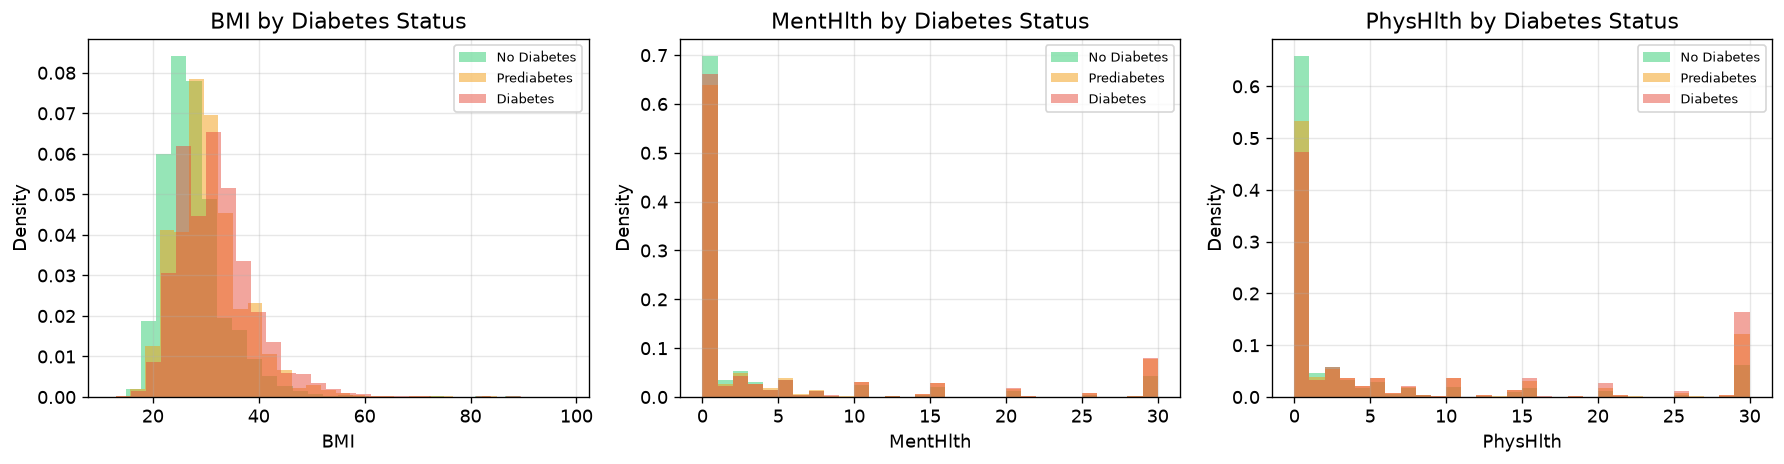

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(CONTINUOUS_FEATURES):
    for cls in range(N_CLASSES):
        subset = df[df[TARGET_COL] == cls][col]
        axes[i].hist(subset, bins=30, alpha=0.5, label=CLASS_NAMES[cls],
                     color=CLASS_COLOURS[cls], density=True)
    axes[i].set_title(f"{col} by Diabetes Status")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Density")
    axes[i].legend(fontsize=8)

plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_continuous_distributions.png"))
plt.show()


### 3.1.2 Binary Feature Prevalence by Class

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_binary_prevalence.png


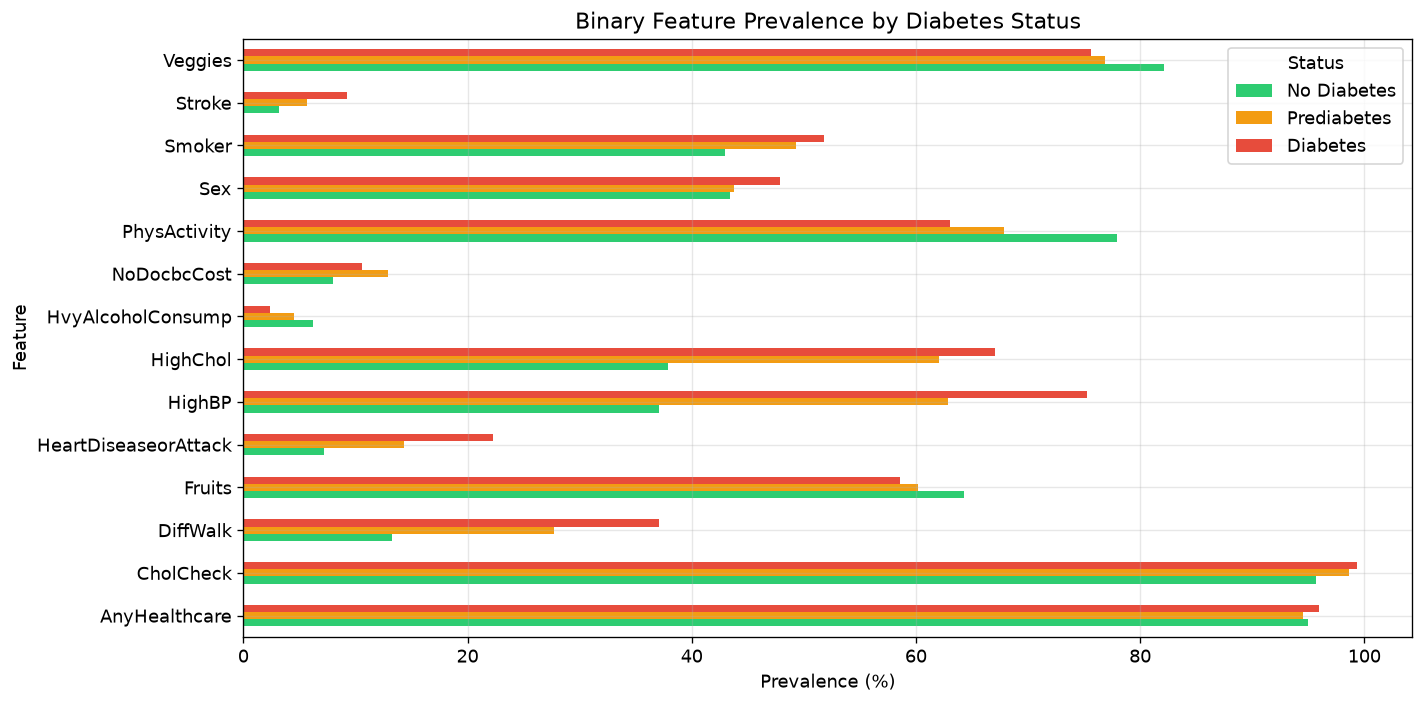


Key observations:
- HighBP prevalence increases dramatically from No Diabetes → Diabetes
- HighChol shows similar trend
- DiffWalk prevalence is much higher in Diabetes class
- PhysActivity is lower in Diabetes class


In [3]:
# Calculate prevalence of binary features by class
prevalence_data = []
for feat in BINARY_FEATURES:
    for cls in range(N_CLASSES):
        subset = df[df[TARGET_COL] == cls]
        prev = subset[feat].mean() * 100
        prevalence_data.append({"Feature": feat, "Class": CLASS_NAMES[cls], "Prevalence_pct": prev})

prev_df = pd.DataFrame(prevalence_data)
prev_pivot = prev_df.pivot(index="Feature", columns="Class", values="Prevalence_pct")
prev_pivot = prev_pivot[CLASS_NAMES]  # Order columns

fig, ax = plt.subplots(figsize=(12, 6))
prev_pivot.plot(kind="barh", ax=ax, color=[CLASS_COLOURS[i] for i in range(N_CLASSES)])
ax.set_xlabel("Prevalence (%)")
ax.set_title("Binary Feature Prevalence by Diabetes Status")
ax.legend(title="Status")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_binary_prevalence.png"))
plt.show()

# Save table
prev_pivot.round(2).to_csv(os.path.join(RESULTS_TABLES, "03_binary_prevalence.csv"))
print("\nKey observations:")
print("- HighBP prevalence increases dramatically from No Diabetes → Diabetes")
print("- HighChol shows similar trend")
print("- DiffWalk prevalence is much higher in Diabetes class")
print("- PhysActivity is lower in Diabetes class")


### 3.1.3 Ordinal Feature Distributions

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_ordinal_distributions.png


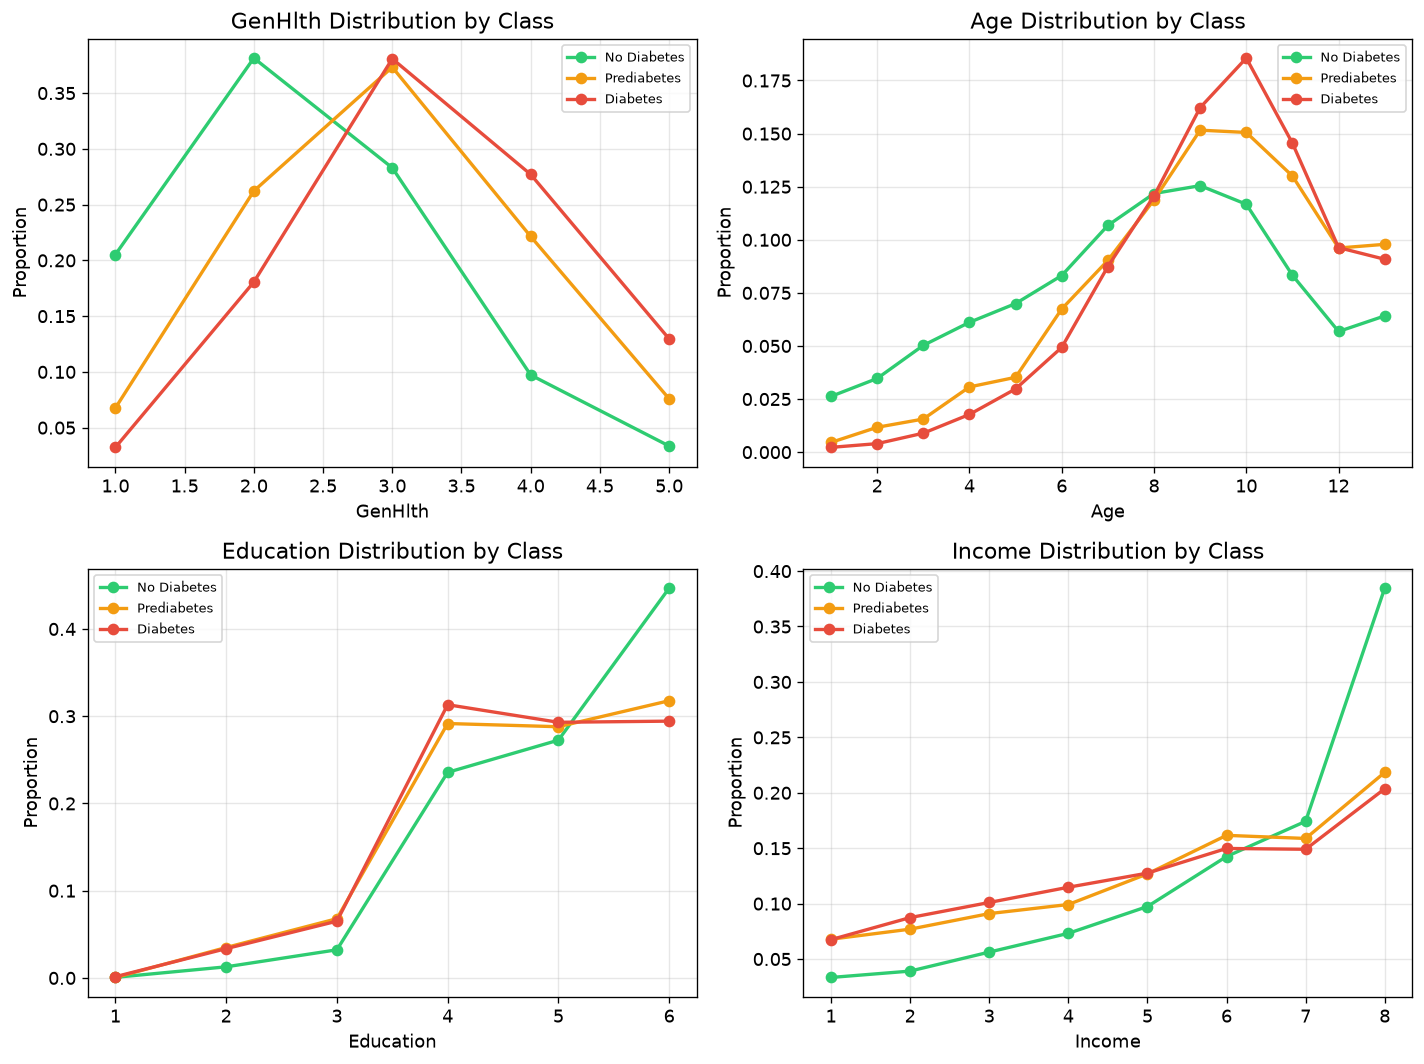

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()
for i, col in enumerate(ORDINAL_FEATURES):
    for cls in range(N_CLASSES):
        subset = df[df[TARGET_COL] == cls][col]
        counts = subset.value_counts(normalize=True).sort_index()
        axes[i].plot(counts.index, counts.values, marker='o', label=CLASS_NAMES[cls],
                     color=CLASS_COLOURS[cls], linewidth=2)
    axes[i].set_title(f"{col} Distribution by Class")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Proportion")
    axes[i].legend(fontsize=8)

plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_ordinal_distributions.png"))
plt.show()


## 3.2 Bivariate Analysis

### 3.2.1 BMI vs Diabetes Status

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_bmi_vs_target.png


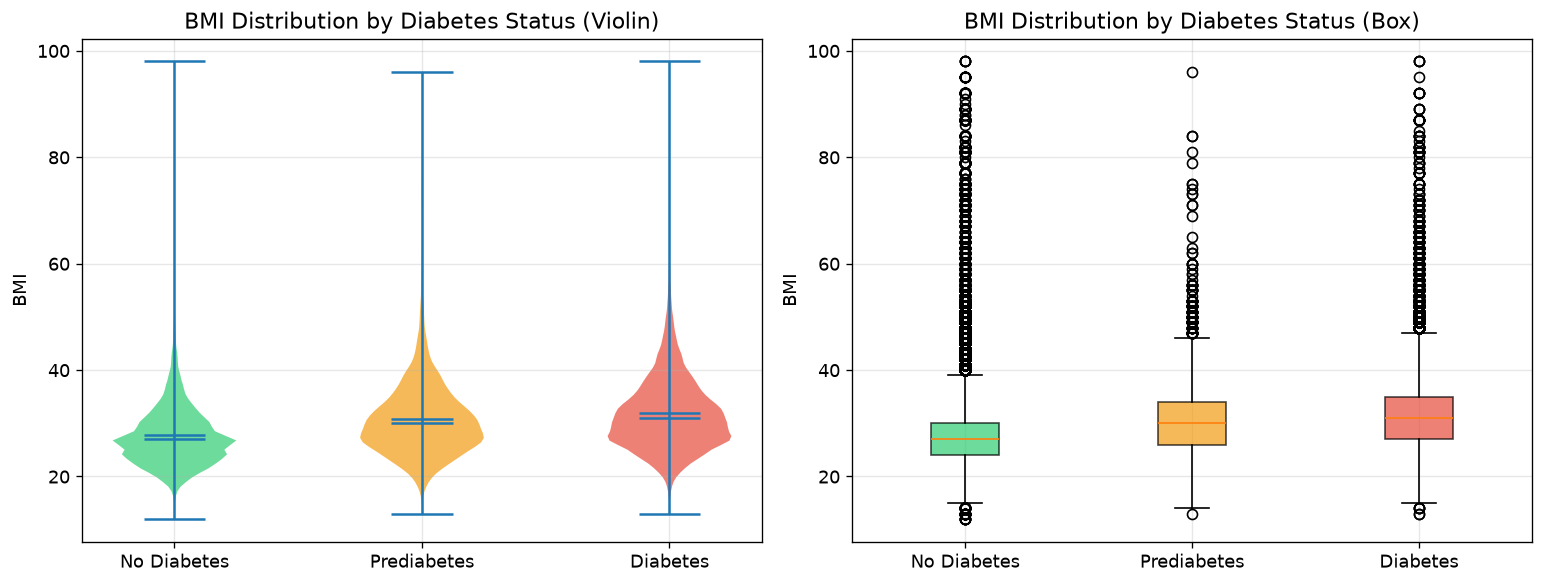

No Diabetes: median BMI=27.0, mean BMI=27.7
Prediabetes: median BMI=30.0, mean BMI=30.7
Diabetes: median BMI=31.0, mean BMI=31.9


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Violin plot
parts = axes[0].violinplot(
    [df[df[TARGET_COL]==c]["BMI"].values for c in range(N_CLASSES)],
    positions=range(N_CLASSES), showmeans=True, showmedians=True
)
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(CLASS_COLOURS[i])
    pc.set_alpha(0.7)
axes[0].set_xticks(range(N_CLASSES))
axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_ylabel("BMI")
axes[0].set_title("BMI Distribution by Diabetes Status (Violin)")

# Box plot
bp_data = [df[df[TARGET_COL]==c]["BMI"].values for c in range(N_CLASSES)]
bp = axes[1].boxplot(bp_data, tick_labels=CLASS_NAMES, patch_artist=True)
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(CLASS_COLOURS[i])
    patch.set_alpha(0.7)
axes[1].set_ylabel("BMI")
axes[1].set_title("BMI Distribution by Diabetes Status (Box)")

plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_bmi_vs_target.png"))
plt.show()

# Report medians
for cls in range(N_CLASSES):
    med = df[df[TARGET_COL]==cls]["BMI"].median()
    mean = df[df[TARGET_COL]==cls]["BMI"].mean()
    print(f"{CLASS_NAMES[cls]}: median BMI={med}, mean BMI={mean:.1f}")


### 3.2.2 Age vs Diabetes Status

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_age_vs_target.png


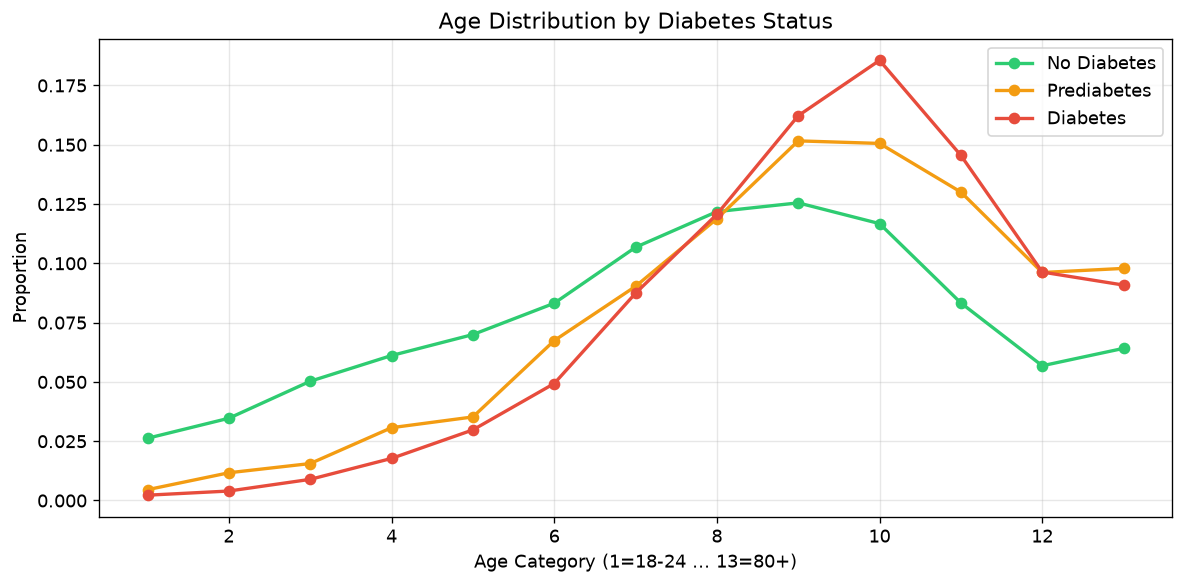

Observation: Diabetes prevalence increases markedly with age category.


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for cls in range(N_CLASSES):
    subset = df[df[TARGET_COL] == cls]
    age_dist = subset["Age"].value_counts(normalize=True).sort_index()
    ax.plot(age_dist.index, age_dist.values, marker='o', label=CLASS_NAMES[cls],
            color=CLASS_COLOURS[cls], linewidth=2)
ax.set_xlabel("Age Category (1=18-24 … 13=80+)")
ax.set_ylabel("Proportion")
ax.set_title("Age Distribution by Diabetes Status")
ax.legend()
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_age_vs_target.png"))
plt.show()
print("Observation: Diabetes prevalence increases markedly with age category.")


### 3.2.3 General Health vs Diabetes Status

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_genhlth_vs_target.png


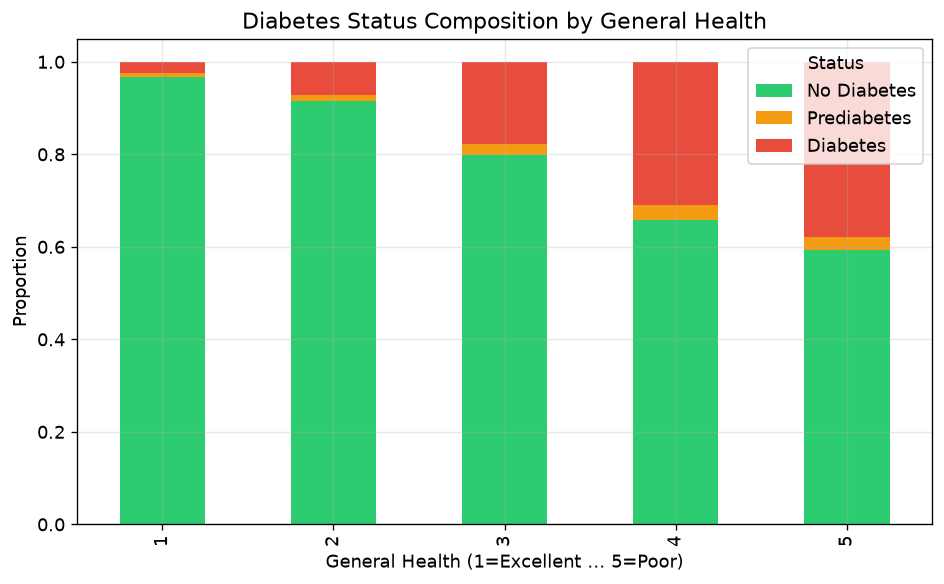

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
cross = pd.crosstab(df["GenHlth"], df[TARGET_COL], normalize="index")
cross.columns = CLASS_NAMES
cross.plot(kind="bar", stacked=True, ax=ax,
           color=[CLASS_COLOURS[i] for i in range(N_CLASSES)])
ax.set_xlabel("General Health (1=Excellent … 5=Poor)")
ax.set_ylabel("Proportion")
ax.set_title("Diabetes Status Composition by General Health")
ax.legend(title="Status")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_genhlth_vs_target.png"))
plt.show()


## 3.3 Multivariate Analysis

### 3.3.1 Correlation Heatmap

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_correlation_heatmap.png


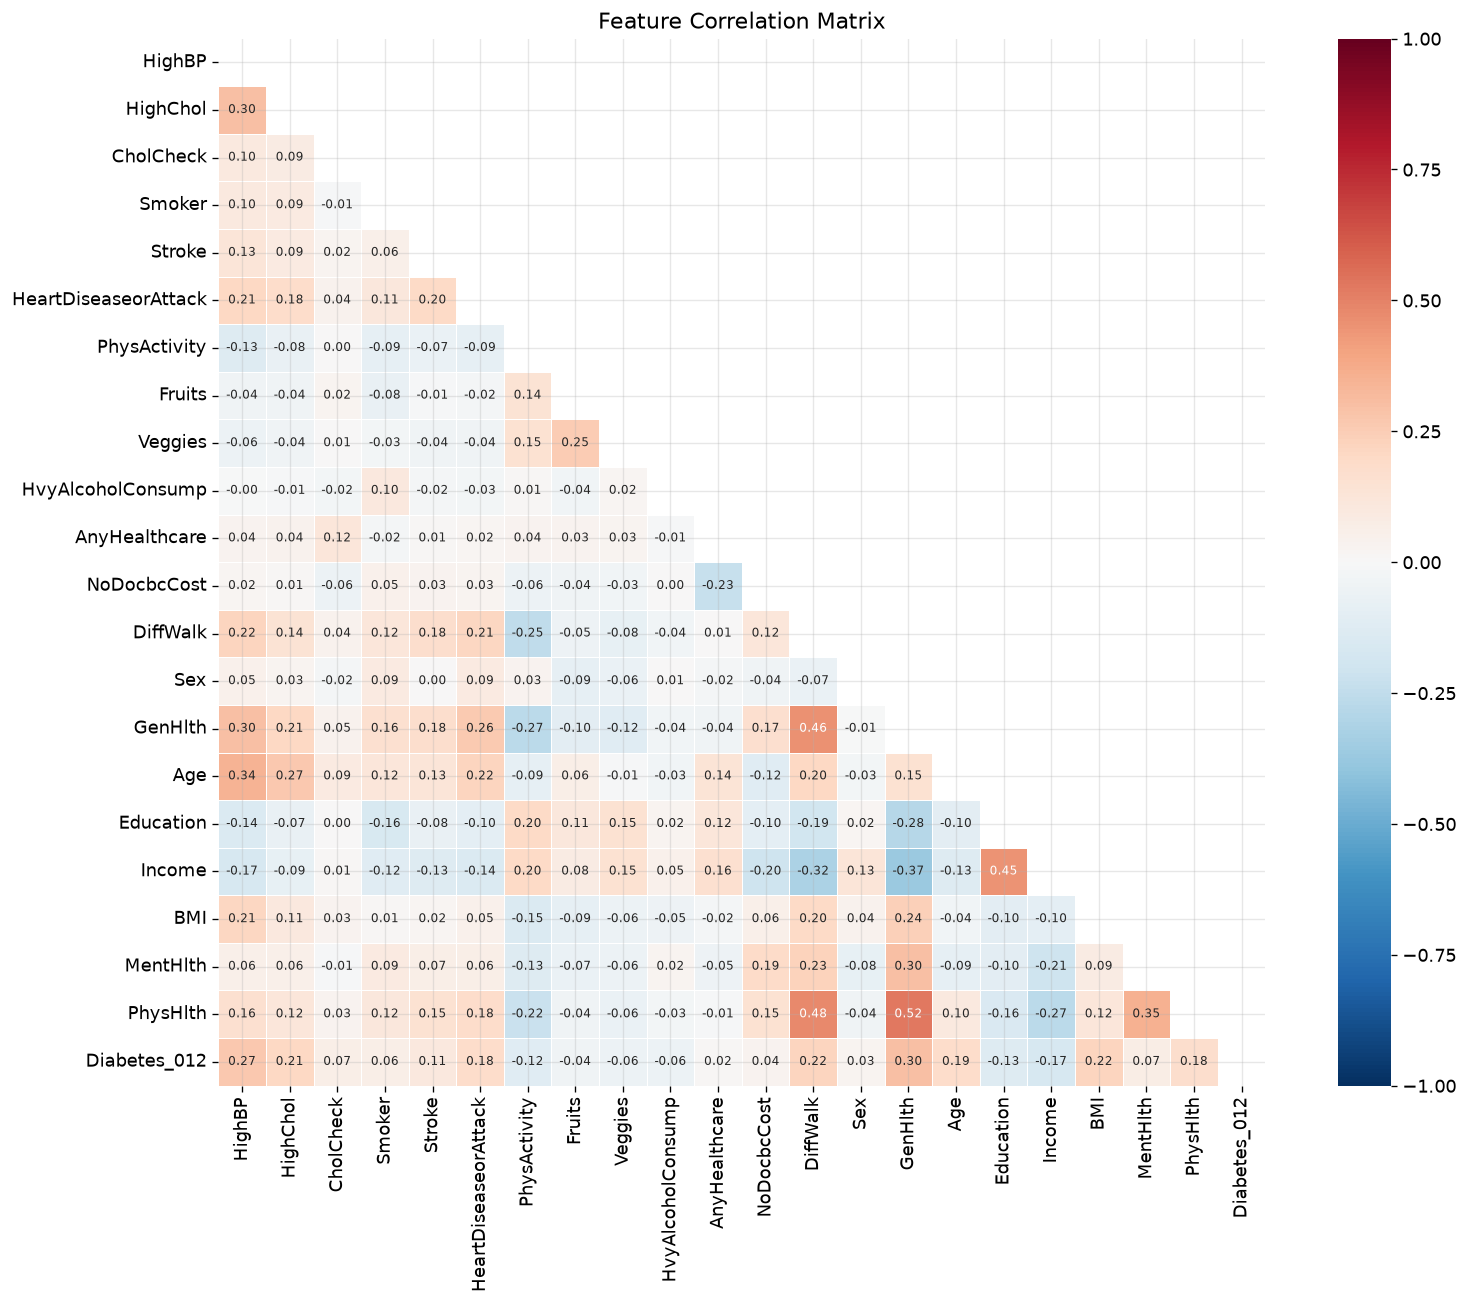

Top correlations with Diabetes_012 (absolute):
GenHlth                 0.303
HighBP                  0.272
BMI                     0.224
DiffWalk                0.224
HighChol                0.209
Age                     0.185
HeartDiseaseorAttack    0.180
PhysHlth                0.176
Income                  0.171
Education               0.131
PhysActivity            0.122
Stroke                  0.107
MentHlth                0.074
CholCheck               0.068
Smoker                  0.063
Veggies                 0.059
HvyAlcoholConsump       0.058
Fruits                  0.042
NoDocbcCost             0.035
Sex                     0.031
AnyHealthcare           0.015


In [8]:
# Correlation matrix
corr = df[ALL_ORIGINAL_FEATURES + [TARGET_COL]].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=ax, square=True,
            linewidths=0.5, annot_kws={"size": 7})
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_correlation_heatmap.png"))
plt.show()

# Top correlations with target
target_corr = corr[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=False)
print("Top correlations with Diabetes_012 (absolute):")
print(target_corr.round(3).to_string())


### 3.3.2 PCA Visualization

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\03_pca_2d.png


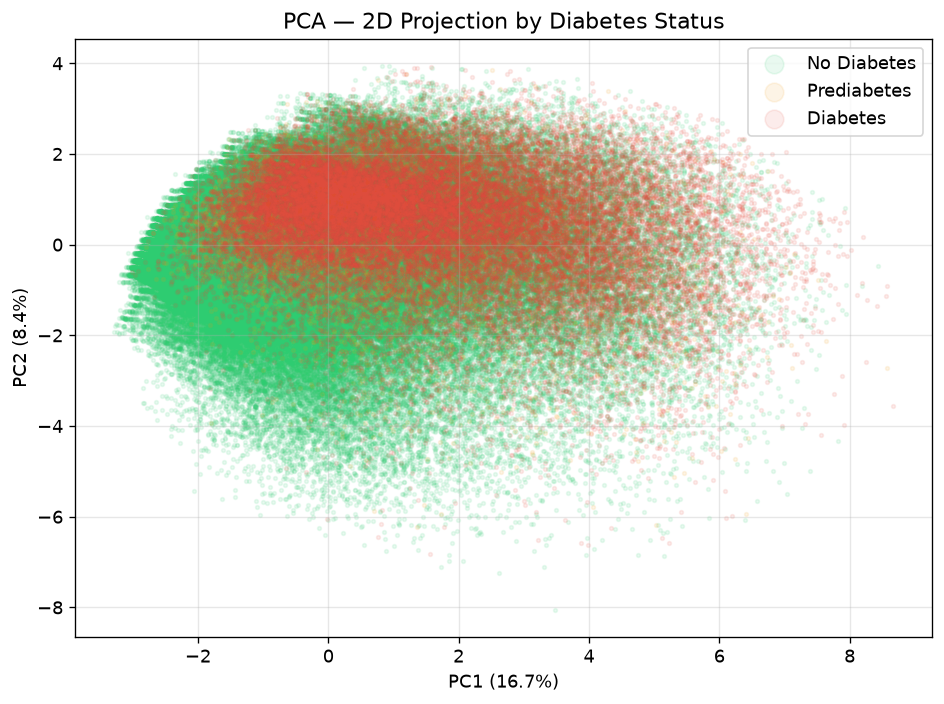

Variance explained by first 2 components: 25.1%
Observation: The classes overlap substantially in PCA space,
confirming that the classification task is non-trivial.


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardise and apply PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[ALL_ORIGINAL_FEATURES])
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
for cls in range(N_CLASSES):
    mask = df[TARGET_COL].values == cls
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.1, s=5,
               label=CLASS_NAMES[cls], color=CLASS_COLOURS[cls])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("PCA — 2D Projection by Diabetes Status")
ax.legend(markerscale=5)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "03_pca_2d.png"))
plt.show()

print(f"Variance explained by first 2 components: "
      f"{pca.explained_variance_ratio_.sum()*100:.1f}%")
print("Observation: The classes overlap substantially in PCA space,")
print("confirming that the classification task is non-trivial.")


### 3.3.3 Interactive Plotly — BMI vs Age vs Target

In [10]:
# Sample for interactive plot (too many points for full dataset)
sample = df.sample(n=5000, random_state=RANDOM_SEED)
sample["Status"] = sample[TARGET_COL].map(CLASS_MAP)

fig = px.scatter(
    sample, x="BMI", y="Age", color="Status",
    color_discrete_map={v: CLASS_COLOURS[k] for k, v in CLASS_MAP.items()},
    opacity=0.5, title="BMI vs Age Category by Diabetes Status (sample n=5000)",
    hover_data=["GenHlth", "HighBP", "HighChol"],
)
fig.update_layout(width=800, height=500)
fig.show()


## 3.4 EDA Summary

**Key findings:**

1. **BMI** is the strongest continuous indicator — Diabetes class has notably higher BMI (median ~32 vs ~27 for No Diabetes).
2. **HighBP** and **HighChol** prevalence are markedly elevated in the Diabetes class.
3. **GenHlth** (general health rating) shows a strong gradient — as self-reported health worsens (1→5), diabetes prevalence increases sharply.
4. **Age** is strongly associated — older age categories have much higher diabetes prevalence.
5. **DiffWalk** (mobility difficulty) is substantially more prevalent in the Diabetes class.
6. **PhysActivity** is lower in the Diabetes class, suggesting less physical activity.
7. **Class overlap** in PCA space confirms that accurate three-class prediction is challenging.
8. **Prediabetes** (Class 1) is difficult to distinguish — its feature distributions often overlap with both No Diabetes and Diabetes classes.

**Next:** Notebook 04 — Statistical Analysis
